# 03 · Autocorrelation of the real waiting times

We want to check whether consecutive waiting times between bursts are independent (Poisson process) or not.

For every threshold of the default grid (20 values between 10³
and 10⁵ SFU):

1. keep the bursts with peak flux ≥ threshold,
2. compute the waiting times between consecutive bursts
   (gaps ≤ 119 s are dropped due to the satellites' distribution, see `srb/config.py`),
3. compute their autocorrelation function (ACF) for all lags.

If the waiting times are independent, about 95% of the ACF values should
fall inside the red band.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt

from srb.config import FIGURES_DIR, THRESHOLD_GRID
from srb.data import inter_event_times_by_threshold, load_catalogue
from srb.diagnostics import acf_confidence_bound, autocorrelation
from srb.plotting import plot_acf_grid

## Parameters

In [2]:
THRESHOLDS = THRESHOLD_GRID  # SFU
MIN_TIMES_FOR_ACF = 2  # the ACF needs at least two values
MAX_LAG = None  # None = all possible lags

## Waiting times for every threshold

In [3]:
df = load_catalogue()
groups = inter_event_times_by_threshold(df, THRESHOLDS, min_count=MIN_TIMES_FOR_ACF)

## ACF for every threshold

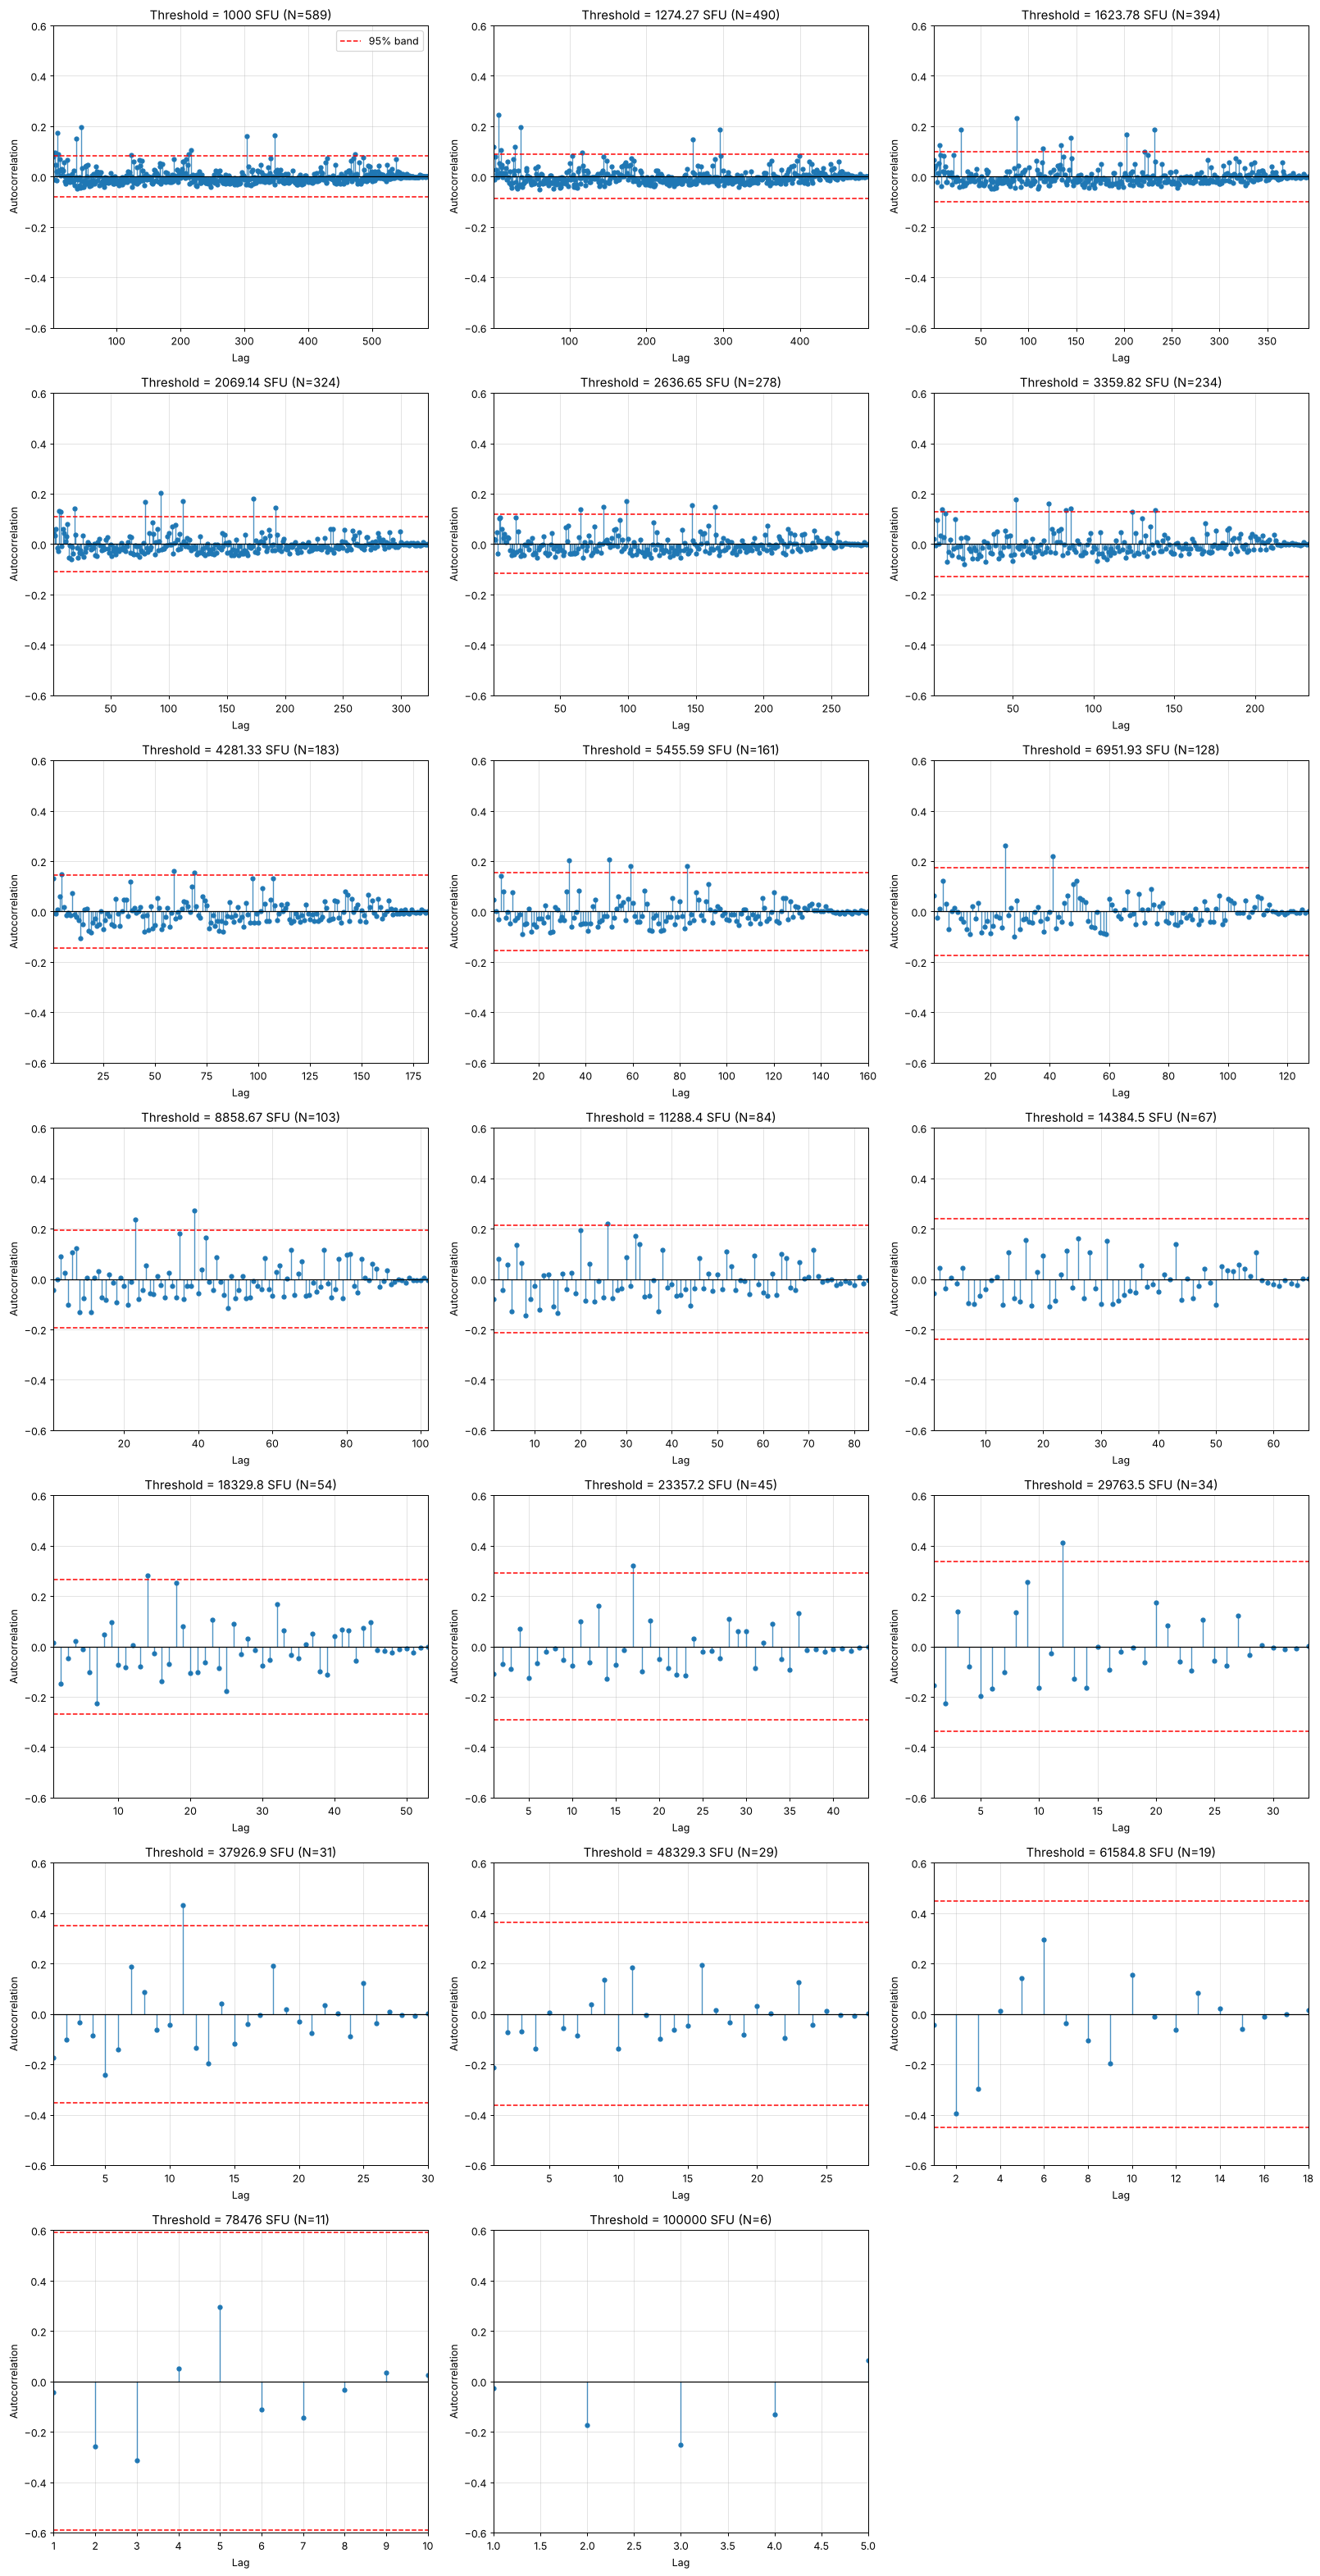

In [4]:
acf_results = []
for threshold, times in groups.items():
    lags, acf = autocorrelation(times, MAX_LAG)
    if lags is None:
        print(f"Cannot compute autocorrelation for threshold {threshold:g} SFU")
        continue
    acf_results.append({
        "threshold": threshold,
        "n": len(times),
        "lags": lags,
        "acf": acf,
        "bound": acf_confidence_bound(len(times)),
    })

fig = plot_acf_grid(acf_results)
fig.savefig(FIGURES_DIR / "acf_by_threshold.png", dpi=300, bbox_inches="tight")
plt.show()